# Nhiệm vụ 2: Phân khúc & Phân cụm bằng K-Means

Đầu vào: `cgv_eda_cleaned.csv` (dữ liệu chính) và `cgv_pca_result.csv` (đặc trưng sau PCA từ Task 1, cùng thứ tự dòng).

Các bước:
1. Lựa chọn K tối ưu: phương pháp khuỷu tay (WCSS) + phân tích Silhouette
2. So sánh mô hình: K-Means trên đặc trưng **đã giảm chiều bằng PCA** và trên **đặc trưng gốc** (chưa giảm chiều)
3. Đầu ra trực quan: scatter 2D/3D tô màu theo cụm, ánh xạ cột `Cluster_Label` vào bộ dữ liệu chính

## 1. Đọc dữ liệu

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

df = pd.read_csv("cgv_eda_cleaned.csv", encoding="utf-8-sig")
X_pca = pd.read_csv("cgv_pca_result.csv", encoding="utf-8-sig")

assert len(df) == len(X_pca), "Hai file phải có cùng số dòng và cùng thứ tự"
print("Dữ liệu chính:", df.shape)
print("Dữ liệu sau PCA:", X_pca.shape)

Dữ liệu chính: (1172, 18)
Dữ liệu sau PCA: (1172, 15)


## 2. Dựng lại đặc trưng gốc (chưa giảm chiều)

Dùng đúng cách tạo đặc trưng và chuẩn hóa `StandardScaler` như Task 1 để so sánh công bằng với dữ liệu PCA.

In [2]:
feat = pd.DataFrame(index=df.index)

for col in ["TicketPrice", "AvailableSeats", "TotalSeats", "DurationMinutes"]:
    feat[col] = pd.to_numeric(df[col], errors="coerce")

feat["OccupancyRate"] = (df["TotalSeats"] - df["AvailableSeats"]) / df["TotalSeats"]
t = pd.to_datetime(df["ShowTime"], format="%H:%M", errors="coerce")
feat["ShowHour"] = t.dt.hour + t.dt.minute / 60

show_date = pd.to_datetime(df["ShowDate"], format="%Y-%m-%d", errors="coerce")
release_date = pd.to_datetime(df["ReleaseDate"], format="%Y-%m-%d", errors="coerce")
feat["DaysSinceRelease"] = (show_date - release_date).dt.days
feat["IsWeekend"] = (show_date.dt.dayofweek >= 5).astype(int)

fmt = df["Format"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df["FormatTech"] = fmt.str.split(r" Phụ| Lồng", n=1, regex=True).str[0].str.strip()
feat["IsPremiumRoom"] = fmt.str.contains(r"\|", regex=True).astype(int)

cat_dummies = pd.get_dummies(df[["Cinema", "Rating", "FormatTech"]], dtype=int)
genre_dummies = df["Genre"].str.get_dummies(sep=", ").add_prefix("Genre_")

X_orig = pd.concat([feat, cat_dummies, genre_dummies], axis=1)
X_orig_scaled = StandardScaler().fit_transform(X_orig)

M_pca = X_pca.values
M_orig = X_orig_scaled

print("Đặc trưng gốc (đã chuẩn hóa):", M_orig.shape)
print("Đặc trưng PCA:", M_pca.shape)

Đặc trưng gốc (đã chuẩn hóa): (1172, 33)
Đặc trưng PCA: (1172, 15)


## 3. Lựa chọn K tối ưu

Với mỗi K từ 2 đến 12, huấn luyện K-Means và tính:
- **WCSS** (`inertia_`): tổng bình phương khoảng cách trong cụm, dùng cho biểu đồ khuỷu tay.
- **Silhouette score**: càng cao càng tốt (cụm chặt và tách biệt).

In [3]:
K_RANGE = range(2, 13)

def scan_k(M):
    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(M)
        rows.append({"K": k, "WCSS": km.inertia_,
                     "Silhouette": silhouette_score(M, km.labels_)})
    return pd.DataFrame(rows)

scan_pca = scan_k(M_pca)
scan_orig = scan_k(M_orig)

display(scan_pca.round(4).rename(columns={"WCSS": "WCSS (PCA)", "Silhouette": "Silhouette (PCA)"})
        .merge(scan_orig.round(4).rename(columns={"WCSS": "WCSS (gốc)", "Silhouette": "Silhouette (gốc)"}), on="K"))

c:\Users\Welcome\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\Welcome\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\Welcome\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\Welcome\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak o

,K,WCSS (PCA),Silhouette (PCA),WCSS (gốc),Silhouette (gốc)
0,2,29175.4889,0.3092,32887.0746,0.2903
1,3,24643.8397,0.2580,28557.4545,0.2393
2,4,21424.9597,0.2968,25305.1910,0.2698
3,5,19319.7979,0.3272,23278.6981,0.2140
4,6,17339.9180,0.2729,21207.7979,0.2509
5,7,15631.8283,0.2845,19774.4669,0.2913
6,8,14410.8693,0.3201,17591.8464,0.2903
7,9,13271.1075,0.3353,16728.2173,0.3050
8,10,12071.9838,0.3528,15010.1543,0.3233
9,11,11469.7697,0.2979,14289.1144,0.2666


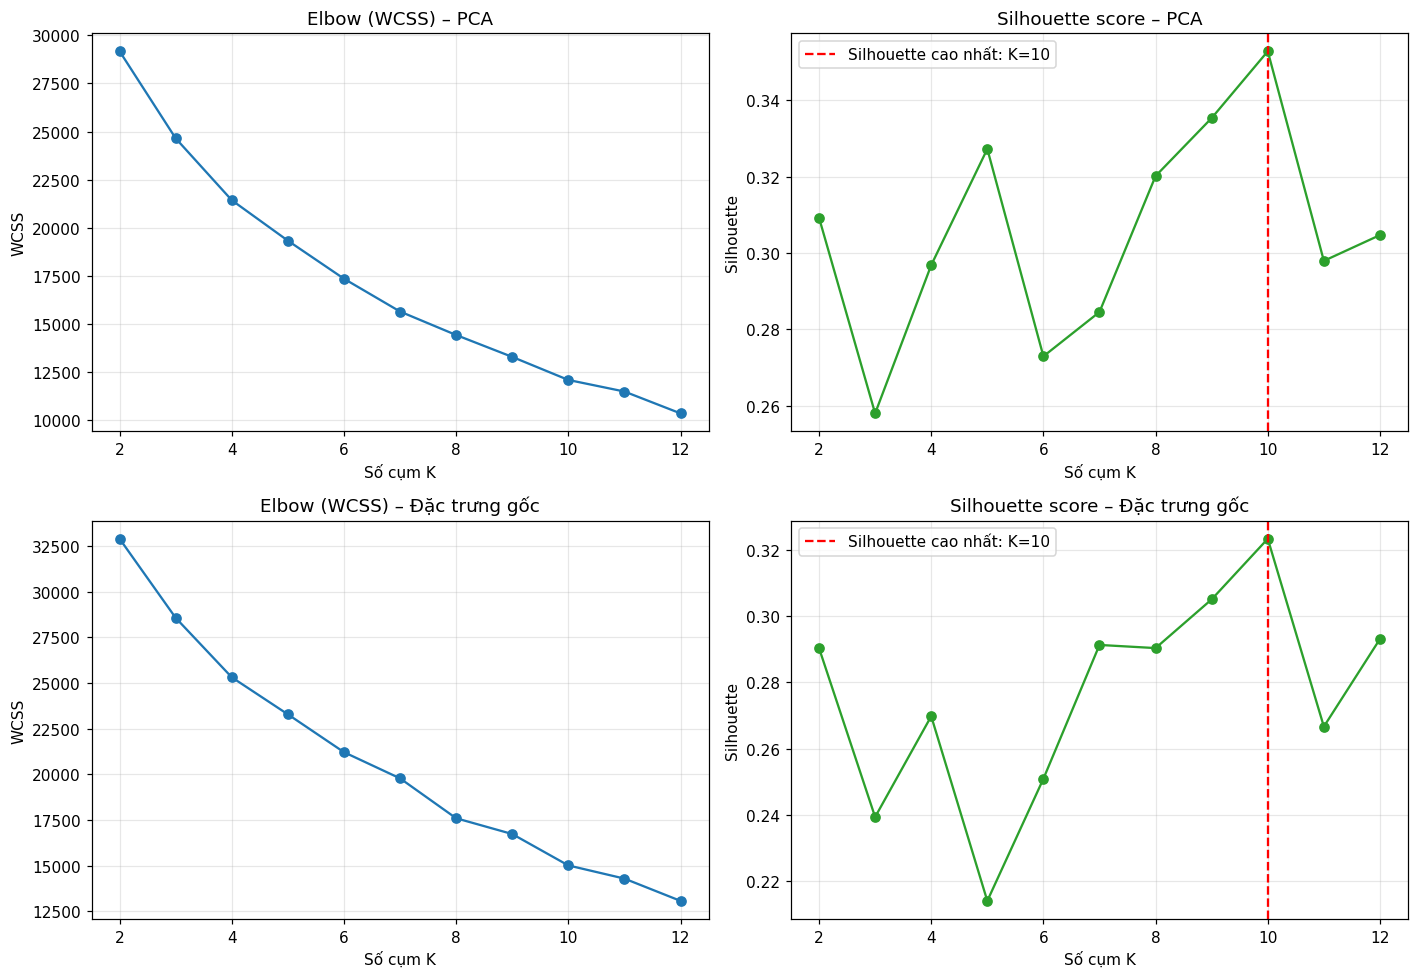

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for row, (name, scan) in enumerate([("PCA", scan_pca), ("Đặc trưng gốc", scan_orig)]):
    axes[row, 0].plot(scan["K"], scan["WCSS"], marker="o", color="#1f77b4")
    axes[row, 0].set_title(f"Elbow (WCSS) – {name}")
    axes[row, 0].set_xlabel("Số cụm K")
    axes[row, 0].set_ylabel("WCSS")
    axes[row, 0].grid(alpha=0.3)

    best_k = int(scan.loc[scan["Silhouette"].idxmax(), "K"])
    axes[row, 1].plot(scan["K"], scan["Silhouette"], marker="o", color="#2ca02c")
    axes[row, 1].axvline(best_k, color="red", linestyle="--", label=f"Silhouette cao nhất: K={best_k}")
    axes[row, 1].set_title(f"Silhouette score – {name}")
    axes[row, 1].set_xlabel("Số cụm K")
    axes[row, 1].set_ylabel("Silhouette")
    axes[row, 1].legend()
    axes[row, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Nhận xét biểu đồ:** Đường WCSS giảm đều, không có điểm khuỷu rõ. Silhouette dao động (0,26–0,35) và có hai đỉnh: K = 5 (0,327) và K = 10 (0,353, cao nhất). Trên đặc trưng gốc Silhouette thấp hơn ở hầu hết các K (đỉnh 0,323 ở K = 10).

In [5]:
# Chọn K: ưu tiên K có Silhouette cao nhất trên dữ liệu PCA trong khoảng K >= 3
# (K = 2 chỉ chia đôi dữ liệu, quá thô để phân khúc).
cand = scan_pca[scan_pca["K"] >= 3]
K_FINAL = int(cand.loc[cand["Silhouette"].idxmax(), "K"])

print(f"K tối ưu (theo Silhouette trên PCA, K>=3): {K_FINAL}")
print("Silhouette tương ứng:", round(float(cand["Silhouette"].max()), 4))
# Muốn thử K khác: gán trực tiếp, ví dụ K_FINAL = 5

K tối ưu (theo Silhouette trên PCA, K>=3): 10
Silhouette tương ứng: 0.3528


**Nhận xét:** K = 10 được chọn vì Silhouette trên PCA cao nhất (0,353) trong khoảng K = 3–12. Silhouette giảm sau K = 10 (K = 11 là 0,298, K = 12 là 0,305). Nếu cần ít phân khúc hơn thì K = 5 (0,327) là đỉnh cục bộ đứng thứ hai, nhưng 10 cụm có ý nghĩa nghiệp vụ rõ hơn (mỗi cụm tương ứng một phim hoặc nhóm phim cùng loại phòng).

**Lưu ý khi đọc biểu đồ:** đường WCSS giảm dần đều (từ 29.175 ở K = 2 xuống 12.072 ở K = 10, mỗi bước giảm khoảng 1.100–4.500) nên **không có điểm khuỷu rõ ràng**. Dữ liệu chủ yếu gồm các biến one-hot nên cần đọc kèm Silhouette và ý nghĩa nghiệp vụ của từng cụm (mục 7) thay vì chỉ dựa vào một chỉ số.

## 4. So sánh mô hình: K-Means trên PCA và K-Means trên đặc trưng gốc

Cả hai mô hình dùng cùng `K = K_FINAL`. Vì hai không gian có số chiều khác nhau nên so sánh theo nhiều góc:
- Chỉ số nội tại trong **chính không gian của mô hình** (Silhouette, Davies-Bouldin, Calinski-Harabasz, WCSS, thời gian chạy).
- **Đánh giá chéo:** chấm Silhouette của cả hai bộ nhãn trên cùng một không gian (gốc, và PCA) để so sánh trực tiếp.
- **ARI** (Adjusted Rand Index) giữa hai bộ nhãn: 1 = trùng khớp hoàn toàn, gần 0 = khác nhau.

In [6]:
def fit_kmeans(M, k):
    start = time.perf_counter()
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(M)
    return km, time.perf_counter() - start

km_pca, t_pca = fit_kmeans(M_pca, K_FINAL)
km_orig, t_orig = fit_kmeans(M_orig, K_FINAL)

labels_pca = km_pca.labels_
labels_orig = km_orig.labels_

compare = pd.DataFrame({
    "Số chiều": [M_pca.shape[1], M_orig.shape[1]],
    "Silhouette (không gian riêng)": [silhouette_score(M_pca, labels_pca), silhouette_score(M_orig, labels_orig)],
    "Davies-Bouldin (thấp hơn = tốt)": [davies_bouldin_score(M_pca, labels_pca), davies_bouldin_score(M_orig, labels_orig)],
    "Calinski-Harabasz (cao hơn = tốt)": [calinski_harabasz_score(M_pca, labels_pca), calinski_harabasz_score(M_orig, labels_orig)],
    "WCSS": [km_pca.inertia_, km_orig.inertia_],
    "Thời gian fit (giây)": [t_pca, t_orig],
}, index=["K-Means trên PCA", "K-Means trên đặc trưng gốc"])

display(compare.round(4))

c:\Users\Welcome\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\Welcome\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


,Số chiều,Silhouette (không gian riêng),Davies-Bouldin (thấp hơn = tốt),Calinski-Harabasz (cao hơn = tốt),WCSS,Thời gian fit (giây)
K-Means trên PCA,15,0.3528,1.0573,244.6499,12071.9838,0.0750
K-Means trên đặc trưng gốc,33,0.3233,1.1599,203.5638,15010.1543,0.0676


In [7]:
# Đánh giá chéo: cùng một không gian, chấm cả hai bộ nhãn
cross = pd.DataFrame({
    "Silhouette trong không gian gốc": [silhouette_score(M_orig, labels_pca), silhouette_score(M_orig, labels_orig)],
    "Silhouette trong không gian PCA": [silhouette_score(M_pca, labels_pca), silhouette_score(M_pca, labels_orig)],
}, index=["Nhãn từ K-Means PCA", "Nhãn từ K-Means gốc"])
display(cross.round(4))

ari = adjusted_rand_score(labels_pca, labels_orig)
print(f"ARI giữa hai bộ nhãn: {ari:.4f}")

# Phân bố kích thước cụm
sizes = pd.DataFrame({
    "PCA": pd.Series(labels_pca).value_counts().sort_index(),
    "Gốc": pd.Series(labels_orig).value_counts().sort_index(),
})
sizes.index.name = "Cụm"
display(sizes)

,Silhouette trong không gian gốc,Silhouette trong không gian PCA
Nhãn từ K-Means PCA,0.3233,0.3528
Nhãn từ K-Means gốc,0.3233,0.3528


ARI giữa hai bộ nhãn: 1.0000


,PCA,Gốc
Cụm,,
0,74,165
1,464,153
2,20,112
3,112,27
4,27,464
5,165,31
6,62,74
7,153,64
8,31,62


**Kết quả so sánh (K = 10):**
- Trong không gian riêng, PCA có Silhouette 0,353 so với 0,323 của dữ liệu gốc, Davies-Bouldin 1,06 so với 1,16 (thấp hơn là tốt), Calinski-Harabasz 245 so với 204. Tuy nhiên hai số này được đo ở hai không gian khác nhau (15 chiều và 33 chiều) nên **không so sánh trực tiếp được**.
- Đánh giá chéo cho kết quả **y hệt nhau**: nhãn từ hai mô hình đạt cùng Silhouette 0,323 trong không gian gốc và cùng 0,353 trong không gian PCA.
- **ARI = 1,0000**: hai bộ nhãn trùng khớp hoàn toàn, chỉ khác số thứ tự cụm (ví dụ cụm 1 của PCA có 464 suất, tương ứng cụm 4 của dữ liệu gốc).
- Kết luận: PCA **không làm thay đổi cấu trúc cụm** mà chỉ giảm số chiều từ 33 xuống 15 và giữ lại 90,36% phương sai. Thời gian chạy của hai cách gần như bằng nhau (khoảng 0,02 giây) vì dữ liệu nhỏ, nên lợi ích của PCA ở đây là gọn hơn và thuận tiện cho việc vẽ biểu đồ, không phải nhanh hơn.

## 5. Chọn mô hình cuối và ánh xạ `Cluster_Label` vào bộ dữ liệu chính

In [8]:
# Mô hình cuối: K-Means trên dữ liệu đã giảm chiều bằng PCA
df["Cluster_Label"] = labels_pca

print("Phân bố cụm:")
print(df["Cluster_Label"].value_counts().sort_index())
df[["MovieName", "Cinema", "ShowDate", "ShowTime", "TicketPrice", "Cluster_Label"]].head(10)

Phân bố cụm:
Cluster_Label
0     74
1    464
2     20
3    112
4     27
5    165
6     62
7    153
8     31
9     64
Name: count, dtype: int64


,MovieName,Cinema,ShowDate,ShowTime,TicketPrice,Cluster_Label
0,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,10:30,65000,3
1,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,16:00,70000,3
2,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,21:30,75000,3
3,CHIIKAWA: BÍ MẬT ĐẢO NGƯỜI CÁ,CGV Crescent Mall,2026-10-01,18:00,80000,5
4,HÒN ĐẢO QUÊN LÃNG,CGV Crescent Mall,2026-10-01,19:40,75000,5
5,LAPUTA: LÂU ĐÀI TRÊN KHÔNG,CGV Crescent Mall,2026-10-01,12:50,75000,5
6,LAPUTA: LÂU ĐÀI TRÊN KHÔNG,CGV Crescent Mall,2026-10-01,14:40,65000,5
7,LAPUTA: LÂU ĐÀI TRÊN KHÔNG,CGV Crescent Mall,2026-10-01,17:10,70000,5
8,LÊN HƯƠNG,CGV Crescent Mall,2026-10-01,09:35,70000,0
9,LÊN HƯƠNG,CGV Crescent Mall,2026-10-01,10:20,70000,0


## 6. Đầu ra trực quan: biểu đồ phân tán cụm 2D / 3D

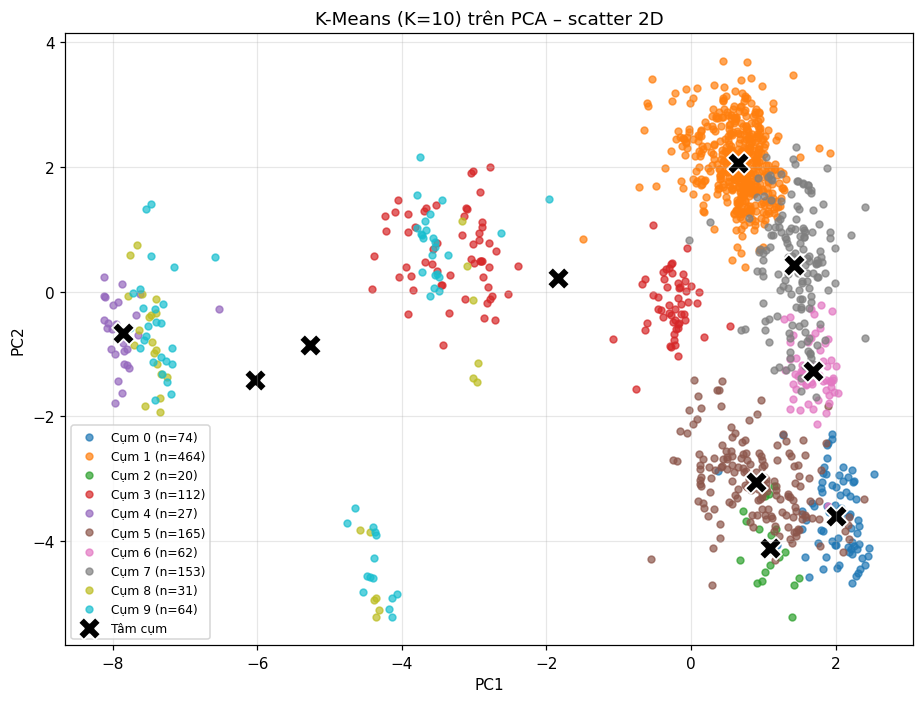

In [9]:
colors = plt.cm.tab10(np.linspace(0, 1, 10))
pc_names = list(X_pca.columns)
evr_note = ""  # tên trục lấy từ cột PCA

fig, ax = plt.subplots(figsize=(8.5, 6.5))
for k in range(K_FINAL):
    mask = (labels_pca == k)
    ax.scatter(X_pca.loc[mask, "PC1"], X_pca.loc[mask, "PC2"],
               s=20, alpha=0.7, color=colors[k], label=f"Cụm {k} (n={mask.sum()})")

centers = km_pca.cluster_centers_
ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=220, c="black",
           edgecolors="white", linewidths=1.2, label="Tâm cụm")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title(f"K-Means (K={K_FINAL}) trên PCA – scatter 2D")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Nhận xét 2D:** Hai thành phần đầu giữ 32,9% phương sai nhưng đã tách rõ nhiều cụm. Các cụm phòng đặc biệt nằm xa nhất về phía PC1 âm (tâm cụm 4, 8, 9 lần lượt ở khoảng −7,9; −6,0; −5,3), cụm 3 ở −1,8, còn các cụm 2D còn lại dồn ở phía PC1 dương (0,65 đến 2,0) nên chồng lấn nhiều hơn. Một số cụm nhìn gần nhau trong 2D chỉ vì hình chiếu, vì K-Means chạy trên 15 chiều; mỗi cụm vẫn tương ứng với một phim hoặc nhóm phim cụ thể (mục 7).

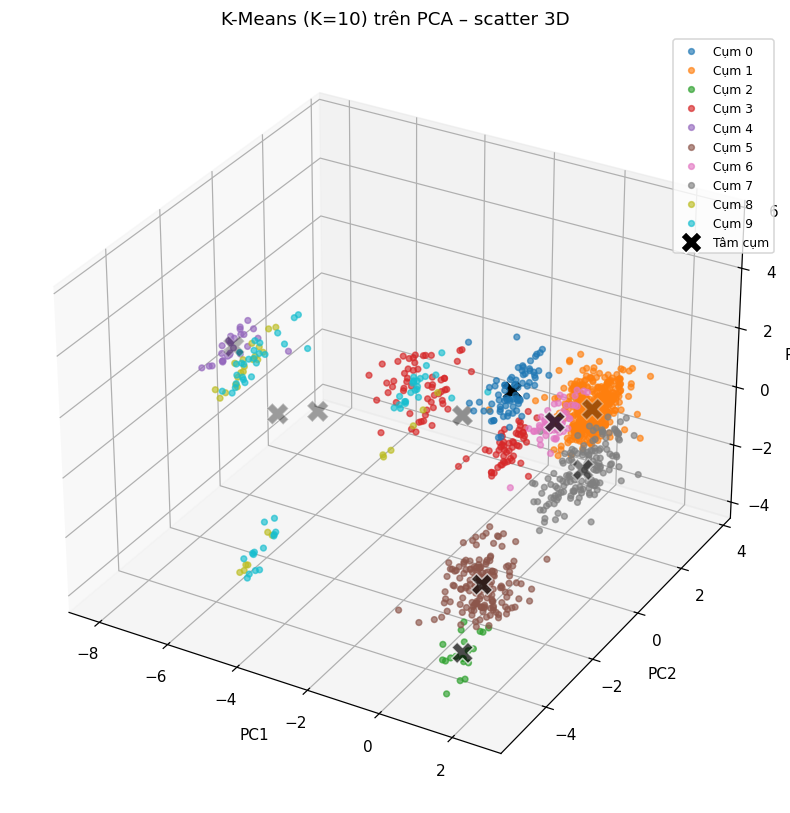

In [10]:
fig = plt.figure(figsize=(9.5, 7.5))
ax = fig.add_subplot(111, projection="3d")
for k in range(K_FINAL):
    mask = (labels_pca == k)
    ax.scatter(X_pca.loc[mask, "PC1"], X_pca.loc[mask, "PC2"], X_pca.loc[mask, "PC3"],
               s=14, alpha=0.65, color=colors[k], label=f"Cụm {k}")
ax.scatter(centers[:, 0], centers[:, 1], centers[:, 2], marker="X", s=200,
           c="black", edgecolors="white", label="Tâm cụm")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title(f"K-Means (K={K_FINAL}) trên PCA – scatter 3D")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Nhận xét 3D:** Thêm PC3 tách các cụm nhãn T16 (cụm 0 và 6, PC3 trung bình +5,0 và +2,2) khỏi các cụm nhãn K (cụm 2 và 5, PC3 trung bình −3,5 và −2,1), những cụm bị chồng về PC1–PC2 ở mặt phẳng 2D. Ba thành phần đầu chỉ giữ 41,7% phương sai nên một số cụm vẫn nhìn gần nhau, dù K-Means chạy trên đủ 15 chiều.

## 7. Đặc điểm từng cụm (hồ sơ phân khúc)

Để diễn giải ý nghĩa nghiệp vụ của mỗi cụm.

In [11]:
profile_num = df.groupby("Cluster_Label").agg(
    So_suat=("Cluster_Label", "size"),
    Gia_ve_TB=("TicketPrice", "mean"),
    Ghe_trong_TB=("AvailableSeats", "mean"),
    Tong_ghe_TB=("TotalSeats", "mean"),
    Thoi_luong_TB=("DurationMinutes", "mean"),
).round(1)

profile_num["Ty_le_lap_day"] = feat["OccupancyRate"].groupby(df["Cluster_Label"]).mean().round(3)
profile_num["Gio_chieu_TB"] = feat["ShowHour"].groupby(df["Cluster_Label"]).mean().round(1)
profile_num["Ngay_tu_phat_hanh_TB"] = feat["DaysSinceRelease"].groupby(df["Cluster_Label"]).mean().round(1)
profile_num["Ty_le_cuoi_tuan"] = feat["IsWeekend"].groupby(df["Cluster_Label"]).mean().round(3)
profile_num["Ty_le_phong_dac_biet"] = feat["IsPremiumRoom"].groupby(df["Cluster_Label"]).mean().round(3)
display(profile_num)

,So_suat,Gia_ve_TB,Ghe_trong_TB,Tong_ghe_TB,Thoi_luong_TB,Ty_le_lap_day,Gio_chieu_TB,Ngay_tu_phat_hanh_TB,Ty_le_cuoi_tuan,Ty_le_phong_dac_biet
Cluster_Label,,,,,,,,,,
0,74,74256.8,78.0,99.7,121.0,0.217,16.7,10.2,0.365,0.027
1,464,78609.9,56.6,97.5,135.0,0.417,16.4,3.0,0.440,0.162
2,20,75000.0,76.0,100.0,144.0,0.240,17.1,17.2,0.400,0.000
3,112,77812.5,64.7,100.2,143.5,0.354,16.4,2.2,0.545,0.241
4,27,104814.8,81.8,118.5,183.0,0.308,16.8,3.2,0.370,1.000
5,165,73939.4,78.4,100.1,111.6,0.218,15.0,6.3,0.412,0.000
6,62,78790.3,74.4,100.0,96.0,0.256,16.4,1.3,0.661,0.000
7,153,74902.0,64.9,99.0,98.2,0.343,16.6,8.0,0.346,0.092
8,31,104032.3,87.0,120.0,151.5,0.275,15.7,4.7,0.323,1.000


**Nhận xét bảng số:** Giá vé và số ghế phân thành hai nhóm rõ: ba cụm phòng đặc biệt (4, 8, 9) có giá vé khoảng 104.000 đồng, tổng ghế 118–120, còn bảy cụm 2D có giá 74.000–79.000 đồng và khoảng 100 ghế. Tỉ lệ lấp đầy dao động từ 0,22 đến 0,42 và cao nhất ở cụm 'Trại buồn người' (cụm 1). Thời lượng trung bình khác nhau theo phim (từ 96 phút ở cụm 6 đến 183 phút ở cụm 4). Số ngày từ phát hành cũng khác rõ: cụm 2 là 17 ngày và cụm 0 là 10 ngày (phim đã ra mắt lâu), trong khi cụm 6 chỉ 1,3 ngày.

In [12]:
def top_values(col, n=2):
    out = {}
    for k, g in df.groupby("Cluster_Label"):
        vc = g[col].value_counts(normalize=True).head(n)
        out[k] = "; ".join(f"{idx} ({v:.0%})" for idx, v in vc.items())
    return pd.Series(out)

profile_cat = pd.DataFrame({
    "Phim_chinh": top_values("MovieName"),
    "Rap_chinh": top_values("Cinema"),
    "Rating_chinh": top_values("Rating"),
    "Dinh_dang_chinh": top_values("FormatTech"),
})
pd.set_option("display.max_colwidth", 80)
display(profile_cat)

,Phim_chinh,Rap_chinh,Rating_chinh,Dinh_dang_chinh
0,LÊN HƯƠNG (100%),CGV Crescent Mall (42%); CGV Hùng Vương Plaza (20%),T16 (100%),2D (100%)
1,TRẠI BUÔN NGƯỜI (100%),CGV Hùng Vương Plaza (32%); CGV Crescent Mall (25%),T18 (100%),2D (100%)
2,BÁT TIÊN ! TRUY TÌM LƯU LY ĐĂNG (100%),CGV Thảo Điền Pearl (65%); CGV Vivo City (35%),K (100%),2D (100%)
3,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU LẠI) (52%); TRÁI TIM QUÁI THÚ ...,CGV Thảo Điền Pearl (41%); CGV Crescent Mall (37%),T13 (100%),2D (100%)
4,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU LẠI) (100%),CGV Vivo City (100%),T13 (100%),IMAX2D (100%)
5,LAPUTA: LÂU ĐÀI TRÊN KHÔNG (39%); MARNIE YÊU DẤU (30%),CGV Thảo Điền Pearl (28%); CGV Crescent Mall (25%),K (87%); p (13%),2D (100%)
6,ÁN MẠNG KARAOKE (97%); BÓNG MA NHÀ HÁT (3%),CGV Vivo City (35%); CGV Crescent Mall (34%),T16 (100%),2D (100%)
7,VÙNG ĐẤT QUỶ DỮ (68%); ÚT LAN 2 (32%),CGV Crescent Mall (29%); CGV Thảo Điền Pearl (27%),T18 (100%),2D (100%)
8,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU LẠI) (61%); HÒN ĐẢO QUÊN LÃNG ...,CGV Hùng Vương Plaza (100%),T13 (61%); K (19%),SCREENX-2D (100%)
9,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU LẠI) (41%); TRẠI BUÔN NGƯỜI (38%),CGV Vivo City (52%); CGV Hùng Vương Plaza (48%),T13 (41%); T18 (38%),4DX2D (100%)


**Nhận xét hồ sơ cụm:**
- **Cụm 1** (464 suất): 'Trại buồn người' 100%, nhãn T18, phòng 2D. Tỉ lệ lấp đầy cao nhất (0,42).
- **Cụm 7** (153 suất): 'Vùng đất quỷ dữ' 68% và 'Út Lan 2' 32%, nhãn T18, 2D. Lấp đầy 0,34.
- **Cụm 3** (112 suất): 'Avengers: Hồi kết' 52% và 'Trái tim quái thú' 48%, nhãn T13, 2D, tỉ lệ cuối tuần 0,55.
- **Cụm 5** (165 suất): 5 phim nhãn K, gồm 'Laputa' 39%, 'Marnie yêu dấu' 30% và các phim hoạt hình khác; lấp đầy thấp (0,22), giờ chiếu trung bình sớm nhất (khoảng 15,0 giờ).
- **Cụm 0** (74 suất: 'Lên Hương', T16), **cụm 2** (20 suất: 'Bát Tiên! Truy tìm Lưu Ly Đăng', K) và **cụm 6** (62 suất: 'Án mạng karaoke' 97%, T16, tỉ lệ cuối tuần cao nhất 0,66) là các cụm theo từng phim.
- **Cụm 4** (IMAX, 27 suất, Avengers 100%, chỉ ở CGV Vivo City), **cụm 8** (ScreenX, 31 suất, chỉ ở CGV Hùng Vương Plaza) và **cụm 9** (4DX, 64 suất) là các cụm **phòng đặc biệt**, giá vé trung bình khoảng 104.000 đồng và 118–120 ghế.
- Số suất mỗi cụm khá lệch (từ 20 đến 464) vì lịch chiếu lệch mạnh về vài phim.

## 8. Lưu dữ liệu đã gắn nhãn cụm

In [13]:
df.drop(columns=["FormatTech"]).to_csv("cgv_clustered.csv", index=False, encoding="utf-8-sig")
print("Đã lưu cgv_clustered.csv với cột Cluster_Label")
print("Kích thước:", df.drop(columns=["FormatTech"]).shape)

Đã lưu cgv_clustered.csv với cột Cluster_Label
Kích thước: (1172, 19)


## 9. Kết luận

- **K tối ưu = 10** (Silhouette trên PCA cao nhất, 0,353, trong khoảng K = 3–12). Silhouette đạt đỉnh cục bộ ở K = 10 rồi giảm ở K = 11 (0,298) và K = 12 (0,305). Đường WCSS không có điểm khuỷu rõ nên quyết định dựa vào Silhouette và ý nghĩa nghiệp vụ của cụm. K = 5 (Silhouette 0,327) là phương án thô hơn, đáng cân nhắc nếu cần ít phân khúc hơn.
- Silhouette 0,35 chỉ ở mức cấu trúc cụm **yếu đến vừa**: các cụm tách được nhưng không tách hẳn.
- **PCA không thay đổi cấu trúc cụm**: ARI giữa nhãn từ PCA và từ dữ liệu gốc bằng 1,0 và đánh giá chéo cho kết quả y hệt nhau. PCA chỉ giảm số chiều từ 33 xuống 15 (giữ 90,36% phương sai).
- **Các cụm tách chủ yếu theo phim và loại phòng**: 7 cụm phòng 2D tương ứng với từng phim hoặc nhóm 2–5 phim cùng nhãn tuổi, và 3 cụm phòng đặc biệt (IMAX, ScreenX, 4DX) có giá vé trung bình khoảng 104.000 đồng và 118–120 ghế, cao hơn các cụm 2D (khoảng 74.000–79.000 đồng, 100 ghế).
- Cụm 1 ('Trại buôn người', 464 suất, tỉ lệ lấp đầy 0,42) có tỉ lệ lấp đầy cao nhất; cụm 0 và 5 thấp nhất (khoảng 0,22).
- Nhãn từ mô hình trên PCA được gắn vào `Cluster_Label` và lưu trong `cgv_clustered.csv`.